# 01 · Cadrage et analyse exploratoire
**Projet final S7MOI1 — Prévoir la consommation électrique du lendemain**

> Les parties marquées **(à adapter)** sont des propositions : relis-les et mets-les à ta main.
> Les parties **Interprétation** sont à compléter *après* avoir exécuté la cellule au-dessus (regarde le graphique, puis écris 1 à 2 phrases).

---
## Axe 1 · Note de cadrage (à adapter)

| Élément | Réponse |
|---|---|
| **Contexte** | Un fournisseur d'énergie (ou une application de suivi énergétique) qui accompagne des foyers. Données : un foyer situé à Sceaux (France), mesures à la minute de décembre 2006 à novembre 2010. Utilisateur final : le responsable de l'achat / de la planification d'énergie. |
| **Problème** | On ne sait pas à l'avance combien d'électricité un foyer consommera demain, ce qui rend l'achat et la planification d'énergie imprécis. |
| **Décision éclairée** | Chaque jour, estimer la consommation totale du lendemain (en kWh) pour ajuster l'achat d'énergie. Horizon : J+1. |
| **Situation actuelle** | Pas de modèle : on suppose « demain = aujourd'hui » (ou « même jour que la semaine dernière »). C'est notre **baseline**. |
| **Critère de succès** | Réduire l'erreur moyenne (MAE) d'au moins 10 % par rapport à la meilleure baseline, sur des données jamais vues. *(seuil à valider avec l'intervenant, à fixer AVANT de regarder le test)* |
| **Contraintes** | Seules les données connues à la fin du jour J-1 sont utilisables ; modèle simple et explicable ; un seul foyer dans les données. |

## Axe 2 · Type de problème
- **Cible** : `Consommation_kWh` du jour J = somme sur 24 h de `Global_active_power / 60` (kW → kWh par minute). Valeur continue, connue pour tout l'historique.
- **Type** : **prévision** (régression sur série temporelle) → split chronologique, variables de retard (lags), `TimeSeriesSplit`.
- **Pourquoi pas les autres ?** Une classification n'a pas de sens (la cible est continue, pas une catégorie). Un clustering ignorerait la cible que l'on connaît. Une régression « classique » avec un split aléatoire mélangerait passé et futur.

## 0 · Imports et configuration

In [ ]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

# Chemins RELATIFS : le projet doit marcher sur n'importe quelle machine
DATA_RAW = Path("data/raw")
DATA_PROCESSED = Path("data/processed")
FIGURES = Path("reports/figures")

for dossier in [DATA_RAW, DATA_PROCESSED, FIGURES]:
    dossier.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (12, 4)

## 1 · Données
**Source** : UCI Machine Learning Repository, *Individual Household Electric Power Consumption* (id 235) — https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
**Date de consultation** : 18/10/2026 *(à vérifier)* · **Licence** : à vérifier sur la page UCI et à citer dans le README.

La cellule ci-dessous télécharge les données automatiquement (reproductibilité). Si le téléchargement échoue (réseau, URL qui change), elle te demande d'importer le ZIP à la main.

In [ ]:
# L'URL de téléchargement est celle du bouton "Download" de la page UCI (à vérifier si elle change)
URL_UCI = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

fichier_txt = DATA_RAW / "household_power_consumption.txt"

if fichier_txt.exists():
    print("Fichier déjà présent :", fichier_txt)
else:
    zip_path = DATA_RAW / "household_power_consumption.zip"
    try:
        import urllib.request
        urllib.request.urlretrieve(URL_UCI, zip_path)
    except Exception as erreur:
        print("Téléchargement automatique impossible :", erreur)
        print("Importe le ZIP téléchargé depuis la page UCI :")
        from google.colab import files
        uploaded = files.upload()
        nom_zip = next(nom for nom in uploaded if nom.lower().endswith(".zip"))
        Path(nom_zip).replace(zip_path)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATA_RAW)

    print("Fichier extrait :", fichier_txt, "-", round(fichier_txt.stat().st_size / 1_000_000, 1), "Mo")

Fichier extrait : data/raw/household_power_consumption.txt - 133.0 Mo


In [ ]:
# "?" = valeur manquante dans ce fichier ; encodage latin1 comme dans ta version
df = pd.read_csv(
    fichier_txt,
    sep=";",
    na_values="?",
    low_memory=False,
    encoding="latin1",
)

# Colonne date + heure (le format précis est plus rapide et plus sûr que dayfirst=True)
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

print("Dimensions du dataset :", df.shape)
print("Période :", df["DateTime"].min(), "->", df["DateTime"].max())
display(df.head())

Dimensions du dataset : (2075259, 10)
Période : 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,DateTime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


### Dictionnaire des variables

| Variable | Type | Unité | Signification |
|---|---|---|---|
| `Date`, `Time` | texte | jj/mm/aaaa, hh:mm:ss | Horodatage de la mesure (1 ligne = 1 minute) |
| `Global_active_power` | float | kW | Puissance active moyenne du foyer sur la minute → **sert à calculer notre cible** |
| `Global_reactive_power` | float | kW | Puissance réactive moyenne |
| `Voltage` | float | V | Tension moyenne |
| `Global_intensity` | float | A | Intensité moyenne |
| `Sub_metering_1` | float | Wh | Cuisine (lave-vaisselle, four, micro-ondes) |
| `Sub_metering_2` | float | Wh | Buanderie (lave-linge, sèche-linge, frigo, lumière) |
| `Sub_metering_3` | float | Wh | Chauffe-eau et climatisation |

## 2 · Qualité des données

In [ ]:
df.info()

print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

print("\nLignes entièrement dupliquées :", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 10 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   object        
 1   Time                   object        
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   DateTime               datetime64[ns]
dtypes: datetime64[ns](1), float64(7), object(2)
memory usage: 158.3+ MB

Valeurs manquantes par colonne :
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3  

In [ ]:
colonnes_mesures = [
    "Global_active_power", "Global_reactive_power", "Voltage",
    "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3",
]

lignes_incompletes = df[colonnes_mesures].isna().any(axis=1).sum()
print("Lignes avec au moins une valeur manquante :", lignes_incompletes,
      "(", round(lignes_incompletes / len(df) * 100, 2), "% )")
print("Lignes où TOUTES les mesures sont manquantes :",
      df[colonnes_mesures].isna().all(axis=1).sum())

# Où sont ces manquants ? On les compte par jour.
df["Jour"] = df["DateTime"].dt.normalize()
manquantes = df[df["Global_active_power"].isna()]
manquantes_par_jour = manquantes.groupby("Jour").size()

print("\nNombre de jours concernés :", len(manquantes_par_jour))
print("Jours dont les 1440 minutes sont manquantes :", (manquantes_par_jour == 1440).sum())
display(manquantes_par_jour.sort_values(ascending=False).head(10))

Lignes avec au moins une valeur manquante : 25979 ( 1.25 % )
Lignes où TOUTES les mesures sont manquantes : 25979

Nombre de jours concernés : 82
Jours dont les 1440 minutes sont manquantes : 9


,0
Jour,
2007-04-29,1440
2009-06-14,1440
2010-01-13,1440
2010-08-21,1440
2010-09-27,1440
2010-09-26,1440
2010-08-20,1440
2010-08-18,1440
2010-08-19,1440


**Interprétation (à compléter)** : combien de lignes manquent, sont-elles isolées ou regroupées par journées entières ? Que dit-on de leur cause (coupure du capteur ?) ?

**Décision de traitement (à justifier)** : on ne garde que les journées complètes (1440 minutes), car une somme sur une journée incomplète sous-estimerait la consommation. On ne remplace pas les trous par une moyenne : on ne veut pas inventer des consommations.

In [ ]:
# Pour chaque jour : combien de mesures, combien de mesures valides ?
bilan_journalier = df.groupby("Jour").agg(
    nombre_lignes=("Global_active_power", "size"),
    mesures_disponibles=("Global_active_power", "count"),
)

jours_complets = bilan_journalier[bilan_journalier["mesures_disponibles"] == 1440].index

print("Nombre de journées au total :", len(bilan_journalier))
print("Journées complètes (1440 mesures valides) :", len(jours_complets))
print("Journées écartées :", len(bilan_journalier) - len(jours_complets))

df_complet = df[df["Jour"].isin(jours_complets)].copy()
print("Lignes conservées :", len(df_complet))

Nombre de journées au total : 1442
Journées complètes (1440 mesures valides) : 1358
Journées écartées : 84
Lignes conservées : 1955520


## 3 · Construction de la cible : consommation journalière en kWh

In [ ]:
# Une mesure en kW sur 1 minute = kW / 60 en kWh. On additionne sur la journée.
df_complet["energie_kWh"] = df_complet["Global_active_power"] / 60

conso = df_complet.groupby("Jour")["energie_kWh"].sum().reset_index()
conso.columns = ["Date", "Consommation_kWh"]
conso = conso.sort_values("Date").reset_index(drop=True)

print("Nombre de journées :", len(conso))
display(conso.head(10))
display(conso["Consommation_kWh"].describe().round(2))

Nombre de journées : 1358


,Date,Consommation_kWh
0,2006-12-17,56.507667
1,2006-12-18,36.730433
2,2006-12-19,27.769900
3,2006-12-20,37.095800
4,2006-12-22,39.022300
5,2006-12-23,79.556433
6,2006-12-24,42.500200
7,2006-12-25,45.718667
8,2006-12-26,65.568500
9,2006-12-27,25.479333


,Consommation_kWh
count,1358.00
mean,25.98
std,9.93
min,4.17
25%,19.43
50%,25.58
75%,31.45
max,79.56


In [ ]:
# Les jours écartés créent des "trous" dans le calendrier : combien ?
ecarts = conso["Date"].diff().dt.days

print("Écarts de 1 jour (consécutifs) :", (ecarts == 1).sum())
print("Écarts supérieurs à 1 jour (trous) :", (ecarts > 1).sum())

# On sauvegarde la table propre pour les notebooks suivants
conso.to_csv(DATA_PROCESSED / "conso_journaliere.csv", index=False)
print("\nSauvegardé :", DATA_PROCESSED / "conso_journaliere.csv")

Écarts de 1 jour (consécutifs) : 1290
Écarts supérieurs à 1 jour (trous) : 67

Sauvegardé : data/processed/conso_journaliere.csv


**Conséquence pour la suite** : à cause des trous, le « jour précédent » ne se trouve pas toujours une ligne plus haut. Dans le notebook 02, les retards seront donc construits **par date** (J-1, J-7) sur un calendrier complet, jamais par simple décalage de lignes.

## 4 · Analyse exploratoire

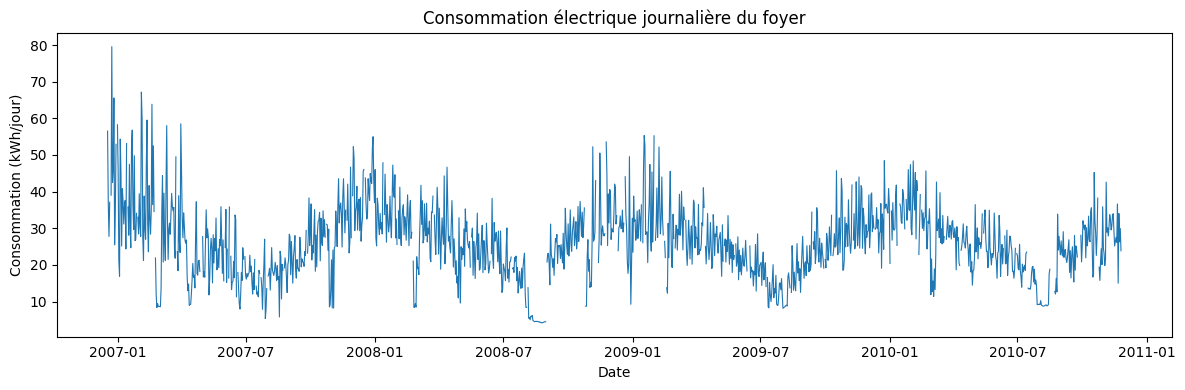

In [ ]:
conso_eda = conso.copy()

# Calendrier complet : les jours manquants apparaissent comme des trous dans la courbe
calendrier = pd.date_range(conso_eda["Date"].min(), conso_eda["Date"].max(), freq="D")
serie = conso_eda.set_index("Date")["Consommation_kWh"].reindex(calendrier)

plt.figure()
plt.plot(serie.index, serie.values, linewidth=0.8)
plt.title("Consommation électrique journalière du foyer")
plt.xlabel("Date")
plt.ylabel("Consommation (kWh/jour)")
plt.tight_layout()
plt.savefig(FIGURES / "01_serie_journaliere.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation (à compléter)** : y a-t-il une saison (hiver vs été) ? Des creux marqués (vacances ?) ? Des ruptures de niveau ? Que cela implique-t-il pour le modèle (variable `mois`) ?

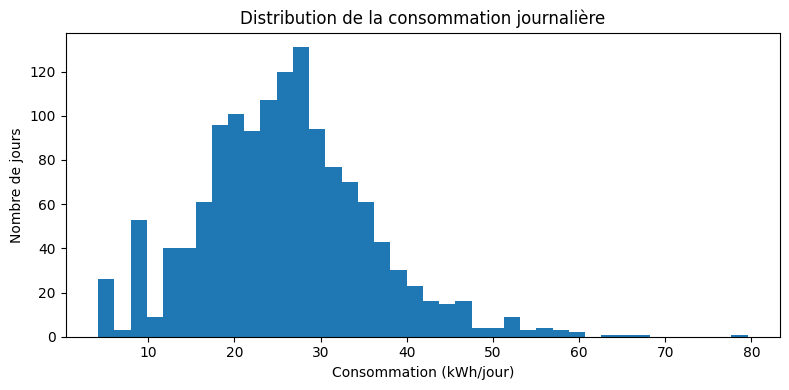

Asymétrie (skewness) : 0.55


In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(conso_eda["Consommation_kWh"], bins=40)
plt.title("Distribution de la consommation journalière")
plt.xlabel("Consommation (kWh/jour)")
plt.ylabel("Nombre de jours")
plt.tight_layout()
plt.savefig(FIGURES / "02_distribution_cible.png", dpi=150, bbox_inches="tight")
plt.show()

print("Asymétrie (skewness) :", round(conso_eda["Consommation_kWh"].skew(), 2))

**Interprétation (à compléter)** : la distribution est-elle symétrique ou étalée vers la droite ? Y a-t-il des valeurs très basses (absence du foyer) ?

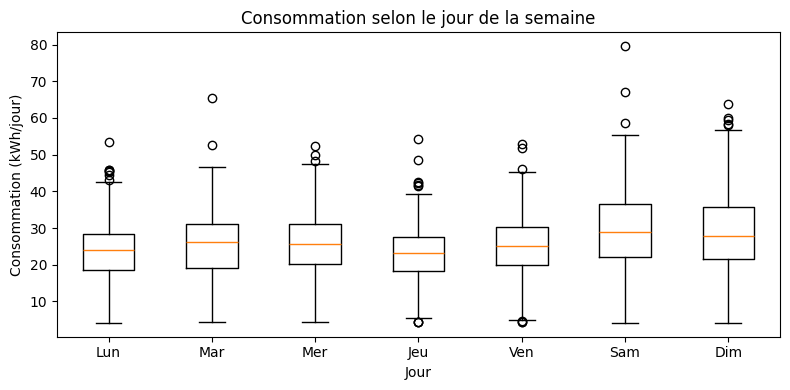

In [ ]:
conso_eda["jour_semaine"] = conso_eda["Date"].dt.dayofweek
conso_eda["mois"] = conso_eda["Date"].dt.month

noms_jours = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
groupes = []
for jour in range(7):
    groupes.append(conso_eda.loc[conso_eda["jour_semaine"] == jour, "Consommation_kWh"])

plt.figure(figsize=(8, 4))
plt.boxplot(groupes)
plt.xticks(range(1, 8), noms_jours)
plt.title("Consommation selon le jour de la semaine")
plt.xlabel("Jour")
plt.ylabel("Consommation (kWh/jour)")
plt.tight_layout()
plt.savefig(FIGURES / "03_jour_semaine.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation (à compléter)** : le week-end consomme-t-il plus ou moins que la semaine ? L'effet est-il assez net pour justifier une variable `week_end` ?

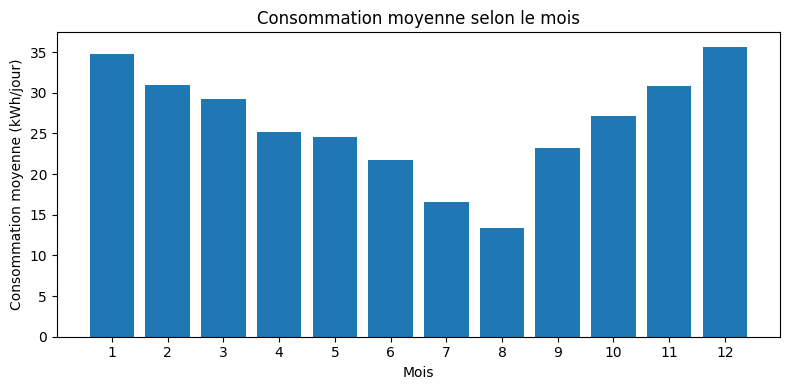

In [ ]:
moyenne_par_mois = conso_eda.groupby("mois")["Consommation_kWh"].mean()

plt.figure(figsize=(8, 4))
plt.bar(moyenne_par_mois.index, moyenne_par_mois.values)
plt.xticks(range(1, 13))
plt.title("Consommation moyenne selon le mois")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne (kWh/jour)")
plt.tight_layout()
plt.savefig(FIGURES / "04_mois.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation (à compléter)** : quels mois consomment le plus ? Est-ce cohérent avec le chauffage en hiver ?

In [ ]:
# La consommation d'aujourd'hui ressemble-t-elle à celle d'hier ? De la semaine dernière ?
for decalage in [1, 2, 7, 14]:
    correlation = serie.corr(serie.shift(decalage))
    print("Corrélation avec la consommation à J-" + str(decalage), ":", round(correlation, 3))

Corrélation avec la consommation à J-1 : 0.616
Corrélation avec la consommation à J-2 : 0.495
Corrélation avec la consommation à J-7 : 0.547
Corrélation avec la consommation à J-14 : 0.468


**Interprétation (à compléter)** : quel retard est le plus corrélé à la cible ? Cela justifie le choix de `Consommation_veille` et `Consommation_semaine_precedente` comme variables.

In [ ]:
print("10 journées les plus faibles :")
display(conso_eda.nsmallest(10, "Consommation_kWh")[["Date", "Consommation_kWh"]])

print("10 journées les plus fortes :")
display(conso_eda.nlargest(10, "Consommation_kWh")[["Date", "Consommation_kWh"]])

10 journées les plus faibles :


,Date,Consommation_kWh
586,2008-08-25,4.171633
584,2008-08-23,4.244033
585,2008-08-24,4.245267
587,2008-08-26,4.292733
588,2008-08-27,4.301900
582,2008-08-21,4.354967
583,2008-08-22,4.452067
590,2008-08-29,4.459800
589,2008-08-28,4.470767
581,2008-08-20,4.474533


10 journées les plus fortes :


,Date,Consommation_kWh
5,2006-12-23,79.556433
44,2007-02-03,67.162033
8,2006-12-26,65.568500
59,2007-02-18,63.829367
45,2007-02-04,59.932333
52,2007-02-11,59.520467
98,2007-03-31,58.491833
12,2006-12-31,58.236600
79,2007-03-11,58.010600
32,2007-01-21,56.787700


# 02 · Modélisation
**Membre 3 — Axes 4 et 5 · Pipeline : variables → split chronologique → baselines → modèles → validation croisée temporelle → test (une seule fois)**

Entrée : `data/processed/features_conso.csv` (préparé par le membre 2). Cible : `Consommation_kWh` du jour (kWh). Chaque ligne contient uniquement des informations connues à la fin du jour précédent (retards J-1 et J-7, calendrier).

Règles respectées : split d'abord, préparation dans un `Pipeline`, baselines à battre, au moins 3 modèles, CV temporelle à 5 plis avec écart-type, réglage d'un hyperparamètre (`max_depth`), **test utilisé une seule fois à la fin**.

**Métriques (axe 5)** : métrique principale = **MAE** (erreur moyenne en kWh, lisible par un décideur, peu sensible aux jours atypiques). Garde-fou = **RMSE** (elle amplifie les grosses erreurs, utile pour repérer les jours très mal prévus). Le R² et le MAPE ne sont pas utilisés : le R² seul ne dit rien en kWh, et le MAPE est instable si la consommation s'approche de 0.

## 0 · Imports et configuration

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_STATE = 42

DATA_PROCESSED = Path("data/processed")
FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (12, 4)

In [6]:
from pathlib import Path

DATA_PROCESSED = Path("data/processed")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
fichier_csv = DATA_PROCESSED / "features_conso.csv"

if fichier_csv.exists():
    print("Fichier déjà présent :", fichier_csv)
else:
    # Cette partie ne marche que dans Colab : elle ouvre une fenêtre d'import
    from google.colab import files
    uploaded = files.upload()   # choisis features_conso.csv sur ton ordinateur
    nom_csv = next(nom for nom in uploaded if nom.endswith(".csv"))
    Path(nom_csv).replace(fichier_csv)
    print("Fichier rangé dans :", fichier_csv)

Saving features_conso.csv to features_conso.csv
Fichier rangé dans : data/processed/features_conso.csv


## 1 · Chargement et variables
Le fichier du membre 2 contient déjà `conso_J_minus_1` et `conso_J_minus_7`, construits **par date** (vérifié : chaque retard correspond bien à la consommation du jour J-1 / J-7 quand ce jour existe). On renomme les colonnes et on ajoute `Moyenne_7_jours` (moyenne des 7 jours précédents), car c'est une baseline forte à tester.

In [7]:
# Fichier préparé par le membre 2 : une ligne = un jour complet,
# avec la consommation du jour (cible) et les retards J-1 et J-7 déjà construits PAR DATE.
conso = pd.read_csv(DATA_PROCESSED / "features_conso.csv", parse_dates=["Date"])
conso = conso.sort_values("Date").reset_index(drop=True)

# On garde les noms de colonnes utilisés dans la suite du notebook
conso = conso.rename(columns={
    "conso_J_minus_1": "Consommation_veille",
    "conso_J_minus_7": "Consommation_semaine_precedente",
    "est_we": "week_end",
})


def ajouter_moyenne_7_jours(conso):
    # Moyenne des 7 jours PRÉCÉDENTS : le shift(1) évite d'inclure le jour à prédire.
    # On travaille sur un calendrier complet : un jour absent devient NaN, pas un faux retard.
    serie = conso.set_index("Date")["Consommation_kWh"]
    calendrier = pd.date_range(serie.index.min(), serie.index.max(), freq="D")
    serie = serie.reindex(calendrier)

    # min_periods=4 : on accepte une fenêtre avec au plus 3 jours manquants
    moyenne = serie.shift(1).rolling(window=7, min_periods=4).mean()

    conso = conso.copy()
    conso["Moyenne_7_jours"] = moyenne.reindex(conso["Date"]).values
    return conso.dropna().reset_index(drop=True)


donnees = ajouter_moyenne_7_jours(conso)

print("Lignes dans le fichier du membre 2 :", len(conso))
print("Journées utilisables (avec Moyenne_7_jours) :", len(donnees))
display(donnees.head())
display(donnees.isna().sum())

Lignes dans le fichier du membre 2 : 1205
Journées utilisables (avec Moyenne_7_jours) : 1163


,Date,Consommation_kWh,jour_semaine,mois,week_end,Consommation_veille,Consommation_semaine_precedente,Moyenne_7_jours
0,2006-12-29,52.906533,4,12,0,34.543967,39.022300,44.816675
1,2007-01-01,45.816733,0,1,0,58.236600,45.718667,47.418258
2,2007-01-02,21.153933,1,1,0,45.816733,65.568500,47.442775
3,2007-01-03,16.900900,2,1,0,21.153933,25.479333,36.339133
4,2007-01-04,54.323533,3,1,0,16.900900,34.543967,34.194525


,0
Date,0
Consommation_kWh,0
jour_semaine,0
mois,0
week_end,0
Consommation_veille,0
Consommation_semaine_precedente,0
Moyenne_7_jours,0


**Interprétation** : on passe de 1 205 lignes à 1 163 journées utilisables car la fenêtre de 7 jours exige au moins 4 jours connus avant la date prédite. Aucune valeur manquante ensuite. Toutes les variables sont connues à la fin du jour J-1 : pas de fuite.

## 2 · Split chronologique (le test = la période la plus récente)
80 % du passé pour apprendre, 20 % du futur pour le test final. **Pas de mélange aléatoire** : le futur ne doit jamais servir à prédire le passé.

In [8]:
donnees = donnees.sort_values("Date").reset_index(drop=True)

limite = int(len(donnees) * 0.8)
train = donnees.iloc[:limite].copy()
test = donnees.iloc[limite:].copy()

colonnes_numeriques = [
    "Consommation_veille",
    "Consommation_semaine_precedente",
    "Moyenne_7_jours",
    "week_end",
]
colonnes_categorielles = ["jour_semaine", "mois"]
variables = colonnes_numeriques + colonnes_categorielles

X_train = train[variables]
y_train = train["Consommation_kWh"]
X_test = test[variables]
y_test = test["Consommation_kWh"]

print("Train :", len(train), "jours,", train["Date"].min().date(), "->", train["Date"].max().date())
print("Test  :", len(test), "jours,", test["Date"].min().date(), "->", test["Date"].max().date())

Train : 930 jours, 2006-12-29 -> 2010-02-02
Test  : 233 jours, 2010-02-03 -> 2010-11-25


## 3 · Modèles et pipelines
- **Baseline 1** : demain = aujourd'hui (situation actuelle).
- **Baseline 2** : demain = même jour la semaine dernière.
- **Baseline 3** : demain = moyenne des 7 derniers jours.
- **Régression linéaire** : `jour_semaine` et `mois` sont des catégories (pas des nombres ordonnés) → `OneHotEncoder` ; les variables numériques sont standardisées. Tout est **dans le Pipeline**, donc ajusté sur le train uniquement.
- **Arbre de décision** et **Random Forest** : pas besoin de standardisation, `max_depth` réglé par validation croisée.

In [9]:
# Régression linéaire avec préparation dans le pipeline
preparation_lineaire = ColumnTransformer([
    ("num", StandardScaler(), colonnes_numeriques),
    ("cat", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles),
])

modele_lineaire = Pipeline([
    ("prep", preparation_lineaire),
    ("reg", LinearRegression()),
])

# Validation croisée temporelle : le passé prédit toujours le futur
tscv = TimeSeriesSplit(n_splits=5)

# Réglage de max_depth de l'arbre (sur le train uniquement, MAE)
grille_arbre = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"max_depth": [2, 3, 4, 5, 8]},
    cv=tscv,
    scoring="neg_mean_absolute_error",
)
grille_arbre.fit(X_train, y_train)

# Réglage de max_depth de la forêt
grille_foret = GridSearchCV(
    RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    param_grid={"max_depth": [3, 5, 8]},
    cv=tscv,
    scoring="neg_mean_absolute_error",
)
grille_foret.fit(X_train, y_train)

print("Arbre - meilleure profondeur :", grille_arbre.best_params_)
print("Forêt - meilleure profondeur :", grille_foret.best_params_)

for nom, grille in [("Arbre", grille_arbre), ("Forêt", grille_foret)]:
    resume = pd.DataFrame(grille.cv_results_)[["param_max_depth", "mean_test_score", "std_test_score"]].copy()
    resume["MAE_val_moy"] = -resume["mean_test_score"]
    resume["MAE_val_ecart_type"] = resume["std_test_score"]
    print("\n" + nom + " : MAE de validation selon max_depth")
    display(resume[["param_max_depth", "MAE_val_moy", "MAE_val_ecart_type"]].round(3))

Arbre - meilleure profondeur : {'max_depth': 4}
Forêt - meilleure profondeur : {'max_depth': 3}

Arbre : MAE de validation selon max_depth


,param_max_depth,MAE_val_moy,MAE_val_ecart_type
0,2,5.806,0.636
1,3,5.680,0.625
2,4,5.677,0.750
3,5,6.022,0.735
4,8,6.599,0.868



Forêt : MAE de validation selon max_depth


,param_max_depth,MAE_val_moy,MAE_val_ecart_type
0,3,5.201,0.433
1,5,5.233,0.607
2,8,5.290,0.630


**Interprétation** : l'arbre retient `max_depth=4` et la forêt `max_depth=3`. Pour l'arbre, une profondeur de 8 dégrade la validation (MAE 6,60 contre 5,68) : c'est du surapprentissage. Pour la forêt, la MAE varie peu (5,20 à 5,29) : le réglage compte moins. Les écarts-types (0,4 à 0,9 kWh) sont du même ordre que les écarts entre profondeurs, donc ces différences ne sont pas très fiables.

## 4 · Comparaison par validation croisée temporelle (sur le train uniquement)

In [11]:
# Une chaîne de caractères = baseline (on recopie la colonne). Sinon = vrai modèle.
modeles = {
    "Baseline : veille": "Consommation_veille",
    "Baseline : même jour semaine précédente": "Consommation_semaine_precedente",
    "Baseline : moyenne 7 jours": "Moyenne_7_jours",
    "Régression linéaire": modele_lineaire,
    "Arbre de décision": grille_arbre.best_estimator_,
    "Random Forest": grille_foret.best_estimator_,
}

lignes = []

for nom, modele in modeles.items():
    maes_train = []
    maes_val = []

    for idx_train, idx_val in tscv.split(X_train):
        X_tr = X_train.iloc[idx_train]
        X_va = X_train.iloc[idx_val]
        y_tr = y_train.iloc[idx_train]
        y_va = y_train.iloc[idx_val]

        if isinstance(modele, str):
            pred_tr = X_tr[modele]
            pred_va = X_va[modele]
            type_modele = "Baseline"
        else:
            modele.fit(X_tr, y_tr)
            pred_tr = modele.predict(X_tr)
            pred_va = modele.predict(X_va)
            type_modele = "Modèle"

        maes_train.append(mean_absolute_error(y_tr, pred_tr))
        maes_val.append(mean_absolute_error(y_va, pred_va))

    lignes.append({
        "Modèle": nom,
        "Type": type_modele,
        "MAE_train_moy": np.mean(maes_train),
        "MAE_val_moy": np.mean(maes_val),
        "MAE_val_ecart_type": np.std(maes_val),
    })

tableau_cv = pd.DataFrame(lignes)
display(tableau_cv.sort_values("MAE_val_moy").round(3))

,Modèle,Type,MAE_train_moy,MAE_val_moy,MAE_val_ecart_type
2,Baseline : moyenne 7 jours,Baseline,6.591,5.064,0.548
5,Random Forest,Modèle,5.266,5.201,0.433
4,Arbre de décision,Modèle,4.923,5.677,0.750
3,Régression linéaire,Modèle,5.642,5.714,2.015
0,Baseline : veille,Baseline,7.578,6.017,0.646
1,Baseline : même jour semaine précédente,Baseline,8.057,6.264,0.597


**Interprétation** :
- La meilleure baseline est la **moyenne 7 jours** (MAE de validation 5,06 kWh). La baseline « veille » (situation actuelle) fait 6,02 kWh.
- Le Random Forest (5,20 ± 0,43) est le meilleur vrai modèle, mais il ne bat pas la moyenne 7 jours (5,06 ± 0,55) : l'écart est plus petit que l'écart-type, donc la différence n'est pas fiable.
- Face à la baseline « veille », le Random Forest gagne environ 14 % en validation (5,20 contre 6,02).
- La régression linéaire est instable (écart-type 2,0 kWh). L'arbre montre un écart train/validation (4,92 contre 5,68) : léger surapprentissage.
- La MAE de validation peut différer de celle du test : les premiers plis s'entraînent sur moins d'un an de données et ne voient pas toutes les saisons.

## 5 · Choix du modèle (d'après la CV, pas d'après le test) et évaluation finale
Le modèle retenu est celui qui a la plus faible `MAE_val_moy` parmi les **vrais modèles**. Le test est utilisé ici, **une seule fois**.

In [12]:
tableau_modeles = tableau_cv[tableau_cv["Type"] == "Modèle"].sort_values("MAE_val_moy")
tableau_baselines = tableau_cv[tableau_cv["Type"] == "Baseline"].sort_values("MAE_val_moy")

nom_retenu = tableau_modeles.iloc[0]["Modèle"]
nom_baseline = tableau_baselines.iloc[0]["Modèle"]       # meilleure baseline selon la CV
colonne_baseline = modeles[nom_baseline]
colonne_veille = modeles["Baseline : veille"]             # situation actuelle du cadrage

print("Modèle retenu (CV) :", nom_retenu)
print("Meilleure baseline (CV) :", nom_baseline)

# Entraînement sur tout le train, puis UN SEUL passage sur le test
modele_final = modeles[nom_retenu]
modele_final.fit(X_train, y_train)

pred_modele = modele_final.predict(X_test)
pred_baseline = X_test[colonne_baseline]
pred_veille = X_test[colonne_veille]

mae_modele = mean_absolute_error(y_test, pred_modele)
rmse_modele = np.sqrt(mean_squared_error(y_test, pred_modele))
mae_baseline = mean_absolute_error(y_test, pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_test, pred_baseline))
mae_veille = mean_absolute_error(y_test, pred_veille)
rmse_veille = np.sqrt(mean_squared_error(y_test, pred_veille))

gain_vs_baseline = (mae_baseline - mae_modele) / mae_baseline * 100
gain_vs_veille = (mae_veille - mae_modele) / mae_veille * 100

print("\n=== RÉSULTATS SUR LE TEST (jamais vu) ===")
print("MAE veille (situation actuelle)  :", round(mae_veille, 2), "kWh   | RMSE :", round(rmse_veille, 2))
print("MAE meilleure baseline           :", round(mae_baseline, 2), "kWh   | RMSE :", round(rmse_baseline, 2))
print("MAE modèle                       :", round(mae_modele, 2), "kWh   | RMSE :", round(rmse_modele, 2))
print("Amélioration de la MAE vs veille (critère : -20 %)  :", round(gain_vs_veille, 1), "%")
print("Amélioration de la MAE vs meilleure baseline        :", round(gain_vs_baseline, 1), "%")
print("MAE modèle / consommation moyenne du test :",
      round(mae_modele / y_test.mean() * 100, 1), "%")

Modèle retenu (CV) : Random Forest
Meilleure baseline (CV) : Baseline : moyenne 7 jours

=== RÉSULTATS SUR LE TEST (jamais vu) ===
MAE veille (situation actuelle)  : 4.82 kWh   | RMSE : 6.78
MAE meilleure baseline           : 4.18 kWh   | RMSE : 5.76
MAE modèle                       : 4.19 kWh   | RMSE : 5.71
Amélioration de la MAE vs veille (critère : -20 %)  : 13.1 %
Amélioration de la MAE vs meilleure baseline        : -0.1 %
MAE modèle / consommation moyenne du test : 17.3 %


**Interprétation** : sur des données jamais vues (3 février → 25 novembre 2010), notre prévision du lendemain se trompe en moyenne de **4,19 kWh**, soit **17,3 %** de la consommation moyenne. La baseline « veille » (situation actuelle) se trompe de 4,82 kWh : le modèle l'améliore de **13,1 %**. En revanche, la moyenne 7 jours fait 4,18 kWh : le modèle ne la bat pas (−0,1 %).

**Le critère de succès provisoire (−20 % de MAE) n'est donc pas atteint**, ni contre la veille (13,1 %), ni contre la meilleure baseline. C'est un résultat recevable, à présenter honnêtement : avec seulement des retards et du calendrier sur un seul foyer, le modèle apporte peu par rapport à une simple moyenne glissante.

## 6 · Diagnostic : erreurs et importance des variables

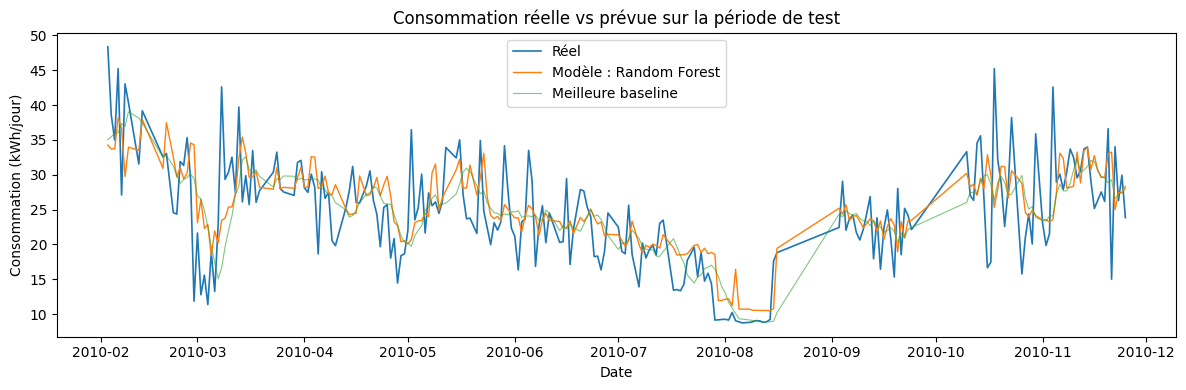

In [13]:
resultats = test[["Date", "Consommation_kWh", "jour_semaine", "mois"]].copy()
resultats = resultats.rename(columns={"Consommation_kWh": "reel"})
resultats["pred_modele"] = pred_modele
resultats["pred_baseline"] = pred_baseline.values
resultats["pred_veille"] = pred_veille.values
resultats["erreur_abs"] = (resultats["reel"] - resultats["pred_modele"]).abs()

plt.figure()
plt.plot(resultats["Date"], resultats["reel"], label="Réel", linewidth=1.2)
plt.plot(resultats["Date"], resultats["pred_modele"], label="Modèle : " + nom_retenu, linewidth=1.0)
plt.plot(resultats["Date"], resultats["pred_baseline"], label="Meilleure baseline", linewidth=0.8, alpha=0.6)
plt.title("Consommation réelle vs prévue sur la période de test")
plt.xlabel("Date")
plt.ylabel("Consommation (kWh/jour)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "05_reel_vs_prevu.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation** : le modèle suit le niveau général mais lisse les pics et les creux. Il ne voit pas les ruptures brutales (absence du foyer, retour de voyage).

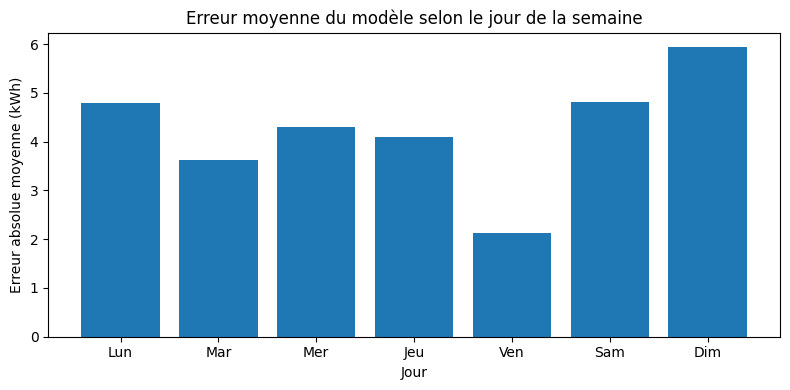

10 plus grosses erreurs :


,Date,reel,pred_modele,erreur_abs
947,2010-02-28,11.86,34.31,22.45
1127,2010-10-18,45.23,25.29,19.94
955,2010-03-08,42.62,23.45,19.17
1141,2010-11-04,42.59,23.58,19.01
1158,2010-11-21,15.02,33.26,18.24
1125,2010-10-16,16.67,32.88,16.21
1002,2010-05-02,36.47,20.70,15.76
930,2010-02-03,48.38,34.26,14.12
949,2010-03-02,12.78,26.47,13.69
935,2010-02-08,43.04,29.75,13.29


In [14]:
# Où le modèle se trompe-t-il le plus ?
noms_jours = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
erreur_par_jour = resultats.groupby("jour_semaine")["erreur_abs"].mean()

plt.figure(figsize=(8, 4))
plt.bar(range(7), erreur_par_jour.reindex(range(7)).values)
plt.xticks(range(7), noms_jours)
plt.title("Erreur moyenne du modèle selon le jour de la semaine")
plt.xlabel("Jour")
plt.ylabel("Erreur absolue moyenne (kWh)")
plt.tight_layout()
plt.savefig(FIGURES / "06_erreur_par_jour.png", dpi=150, bbox_inches="tight")
plt.show()

print("10 plus grosses erreurs :")
display(resultats.nlargest(10, "erreur_abs")[["Date", "reel", "pred_modele", "erreur_abs"]].round({"reel": 2, "pred_modele": 2, "erreur_abs": 2}))

**Interprétation** : les plus grosses erreurs (13 à 22 kWh) tombent sur des jours de rupture : fin février / début mars 2010 (jours à 12-13 kWh, qui ressemblent à une absence du foyer, à vérifier), et plusieurs jours isolés très hauts (18/10, 04/11) ou très bas (21/11, 16/10) que rien dans les retards ne permet d'anticiper. Ce que le modèle ne voit pas : la météo, la présence au foyer, les jours fériés et les vacances.

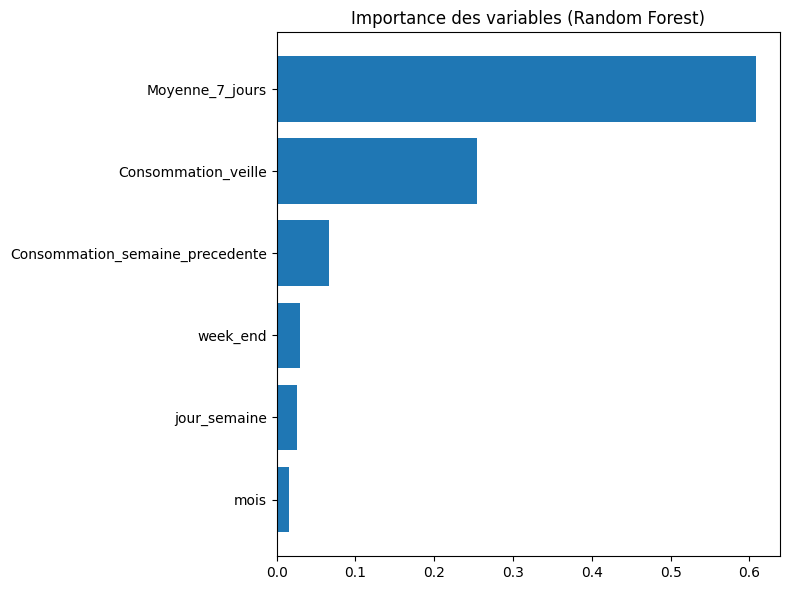

Moyenne_7_jours                    0.61
Consommation_veille                0.25
Consommation_semaine_precedente    0.07
week_end                           0.03
jour_semaine                       0.03
mois                               0.02
dtype: float64


In [15]:
# Importance des variables
if nom_retenu == "Régression linéaire":
    noms = modele_final.named_steps["prep"].get_feature_names_out()
    importances = pd.Series(modele_final.named_steps["reg"].coef_, index=noms)
    titre = "Coefficients de la régression linéaire (variables standardisées)"
else:
    importances = pd.Series(modele_final.feature_importances_, index=variables)
    titre = "Importance des variables (" + nom_retenu + ")"

ordre = importances.abs().sort_values().index
importances = importances.reindex(ordre)

plt.figure(figsize=(8, 6))
plt.barh(importances.index, importances.values)
plt.title(titre)
plt.tight_layout()
plt.savefig(FIGURES / "07_importance_variables.png", dpi=150, bbox_inches="tight")
plt.show()
print(importances.sort_values(ascending=False).round(2))

**Interprétation** : `Moyenne_7_jours` domine nettement (importance 0,61), puis `Consommation_veille` (0,25). `Consommation_semaine_precedente`, `week_end`, `jour_semaine` et `mois` pèsent peu. C'est cohérent avec l'analyse exploratoire (forte corrélation avec J-1 et J-7) et avec le fait que la meilleure baseline est elle-même une moyenne des jours précédents.

## 7 · Sauvegarde des résultats pour le notebook 03 (décision et ROI)
On sauvegarde la baseline « veille » (situation actuelle) en plus de la meilleure baseline, pour que le membre 1 puisse calculer le ROI par rapport à la situation actuelle.

In [16]:
resultats[["Date", "reel", "pred_modele", "pred_baseline", "pred_veille"]].to_csv(
    DATA_PROCESSED / "resultats_test.csv", index=False
)

metriques = pd.DataFrame({
    "indicateur": ["modele_retenu", "baseline_reference", "mae_modele", "mae_baseline", "mae_veille",
                   "rmse_modele", "rmse_baseline", "rmse_veille", "conso_moyenne_test"],
    "valeur": [nom_retenu, nom_baseline, mae_modele, mae_baseline, mae_veille,
               rmse_modele, rmse_baseline, rmse_veille, y_test.mean()],
})
metriques.to_csv(DATA_PROCESSED / "metriques_test.csv", index=False)
tableau_cv.to_csv(DATA_PROCESSED / "comparaison_cv.csv", index=False)
print("Résultats sauvegardés dans", DATA_PROCESSED)

Résultats sauvegardés dans data/processed


# 03 · Décision, coûts et ROI
Axes 6, 7 et 9 : traduire l'erreur du modèle en euros, estimer le gain annuel, tester la sensibilité, lister les risques.

> ⚠️ **Tous les coûts ci-dessous sont des HYPOTHÈSES posées pour illustrer la démarche.** Remplace-les par des valeurs sourcées (tarif du kWh, coût d'écart d'équilibre, etc.) et cite tes sources. Ne présente jamais un ROI comme une certitude.

In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PROCESSED = Path("data/processed")
FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 4)

resultats = pd.read_csv(DATA_PROCESSED / "resultats_test.csv", parse_dates=["Date"])
metriques = pd.read_csv(DATA_PROCESSED / "metriques_test.csv").set_index("indicateur")["valeur"]

print("Modèle retenu :", metriques["modele_retenu"])
print("Baseline de référence :", metriques["baseline_reference"])
print("MAE baseline :", round(float(metriques["mae_baseline"]), 2), "kWh")
print("MAE modèle   :", round(float(metriques["mae_modele"]), 2), "kWh")

Modèle retenu : Random Forest
Baseline de référence : Baseline : moyenne 7 jours
MAE baseline : 4.18 kWh
MAE modèle   : 4.19 kWh


## 1 · Matrice de coûts (hypothèses)
Se tromper dans les deux sens ne coûte pas pareil pour un acheteur d'énergie :
- **Sous-estimation** (on prévoit moins que la réalité) : il faut racheter de l'énergie en urgence, plus cher.
- **Sur-estimation** (on prévoit plus que la réalité) : on a acheté trop, le surplus est revendu à perte ou perdu.

In [18]:
# ----- HYPOTHÈSES (à remplacer par des valeurs sourcées) -----
COUT_SOUS_ESTIMATION = 0.15   # € par kWh manquant (rachat en urgence)
COUT_SUR_ESTIMATION = 0.05    # € par kWh en trop (revente à perte)
NB_FOYERS = 10_000            # nombre de foyers du portefeuille
COUT_DEVELOPPEMENT = 40_000   # € (1re année)
COUT_EXPLOITATION = 15_000    # € (1re année : hébergement, suivi, réentraînement)
# --------------------------------------------------------------


def cout_moyen_par_jour(reel, prevu, cout_sous, cout_sur):
    # erreur > 0 : on a prévu moins que le réel (sous-estimation)
    erreur = reel - prevu
    cout = np.where(erreur > 0, erreur * cout_sous, -erreur * cout_sur)
    return cout.mean()


def bilan(reel, pred_modele, pred_baseline, cout_sous, cout_sur, nb_foyers, cout_projet):
    cout_jour_baseline = cout_moyen_par_jour(reel, pred_baseline, cout_sous, cout_sur)
    cout_jour_modele = cout_moyen_par_jour(reel, pred_modele, cout_sous, cout_sur)

    # Coût annuel du portefeuille = coût moyen par jour et par foyer x 365 x nombre de foyers
    cout_sans_modele = cout_jour_baseline * 365 * nb_foyers
    cout_avec_modele = cout_jour_modele * 365 * nb_foyers

    gain = cout_sans_modele - cout_avec_modele
    roi = (gain - cout_projet) / cout_projet * 100
    if gain > 0:
        delai_mois = cout_projet / (gain / 12)
    else:
        delai_mois = float("inf")

    return {
        "cout_sans_modele": cout_sans_modele,
        "cout_avec_modele": cout_avec_modele,
        "gain_annuel": gain,
        "roi_pct": roi,
        "delai_retour_mois": delai_mois,
    }


reel = resultats["reel"]
pred_modele = resultats["pred_modele"]
pred_baseline = resultats["pred_baseline"]
cout_projet = COUT_DEVELOPPEMENT + COUT_EXPLOITATION

b = bilan(reel, pred_modele, pred_baseline,
          COUT_SOUS_ESTIMATION, COUT_SUR_ESTIMATION, NB_FOYERS, cout_projet)

print("Coût annuel SANS modèle :", round(b["cout_sans_modele"]), "€")
print("Coût annuel AVEC modèle :", round(b["cout_avec_modele"]), "€")
print("Gain annuel             :", round(b["gain_annuel"]), "€")
print("Coût du projet (an 1)   :", cout_projet, "€")
print("ROI an 1                :", round(b["roi_pct"], 1), "%")
print("Délai de retour         :", round(b["delai_retour_mois"], 1), "mois")

Coût annuel SANS modèle : 1489525 €
Coût annuel AVEC modèle : 1379312 €
Gain annuel             : 110213 €
Coût du projet (an 1)   : 55000 €
ROI an 1                : 100.4 %
Délai de retour         : 6.0 mois


**Lecture (à compléter)** : écris « Sous nos hypothèses, le modèle réduit le coût annuel de X € … ». Précise que l'on extrapole **un seul foyer** à un portefeuille de `NB_FOYERS` foyers : c'est l'hypothèse la plus fragile.

## 2 · Scénarios et analyse de sensibilité

In [19]:
scenarios = {
    "Pessimiste": {"sous": 0.05, "sur": 0.02, "foyers": 2_000},
    "Central": {"sous": COUT_SOUS_ESTIMATION, "sur": COUT_SUR_ESTIMATION, "foyers": NB_FOYERS},
    "Optimiste": {"sous": 0.25, "sur": 0.08, "foyers": 20_000},
}

lignes = []
for nom, p in scenarios.items():
    r = bilan(reel, pred_modele, pred_baseline, p["sous"], p["sur"], p["foyers"], cout_projet)
    lignes.append({
        "Scénario": nom,
        "Coût sous-est. (€/kWh)": p["sous"],
        "Coût sur-est. (€/kWh)": p["sur"],
        "Foyers": p["foyers"],
        "Coût sans modèle (€)": round(r["cout_sans_modele"]),
        "Coût avec modèle (€)": round(r["cout_avec_modele"]),
        "Gain annuel (€)": round(r["gain_annuel"]),
        "ROI an 1 (%)": round(r["roi_pct"], 1),
        "Retour (mois)": round(r["delai_retour_mois"], 1),
    })

tableau_roi = pd.DataFrame(lignes)
display(tableau_roi)
tableau_roi.to_csv(DATA_PROCESSED / "tableau_roi.csv", index=False)

,Scénario,Coût sous-est. (€/kWh),Coût sur-est. (€/kWh),Foyers,Coût sans modèle (€),Coût avec modèle (€),Gain annuel (€),ROI an 1 (%),Retour (mois)
0,Pessimiste,0.05,0.02,2000,104632,98039,6593,-88.0,100.1
1,Central,0.15,0.05,10000,1489525,1379312,110213,100.4,6.0
2,Optimiste,0.25,0.08,20000,4911776,4536853,374922,581.7,1.8


In [20]:
# Sensibilité : combien de foyers faut-il pour que le projet soit rentable (ROI = 0) ?
gain_par_foyer = b["gain_annuel"] / NB_FOYERS

if gain_par_foyer > 0:
    foyers_equilibre = cout_projet / gain_par_foyer
    print("Gain annuel par foyer (hypothèses centrales) :", round(gain_par_foyer, 2), "€")
    print("Nombre de foyers pour atteindre l'équilibre :", round(foyers_equilibre))
else:
    print("Avec ces hypothèses, le modèle ne rapporte rien par rapport à la baseline.")

# Grille : gain annuel selon le coût de sous-estimation et le nombre de foyers
couts_sous = [0.05, 0.10, 0.15, 0.25]
nb_foyers_liste = [1_000, 5_000, 10_000, 20_000]

grille = []
for c in couts_sous:
    ligne = []
    for n in nb_foyers_liste:
        r = bilan(reel, pred_modele, pred_baseline, c, COUT_SUR_ESTIMATION, n, cout_projet)
        ligne.append(round(r["gain_annuel"] - cout_projet))
    grille.append(ligne)

grille = pd.DataFrame(
    grille,
    index=["sous-est. " + str(c) + " €/kWh" for c in couts_sous],
    columns=[str(n) + " foyers" for n in nb_foyers_liste],
)
print("\nGain net de la 1re année (gain - coût du projet), en € :")
display(grille)

Gain annuel par foyer (hypothèses centrales) : 11.02 €
Nombre de foyers pour atteindre l'équilibre : 4990

Gain net de la 1re année (gain - coût du projet), en € :


,1000 foyers,5000 foyers,10000 foyers,20000 foyers
sous-est. 0.05 €/kWh,-55100,-55499,-55998,-56996
sous-est. 0.1 €/kWh,-49539,-27696,-393,54215
sous-est. 0.15 €/kWh,-43979,106,55213,165425
sous-est. 0.25 €/kWh,-32858,55712,166423,387846


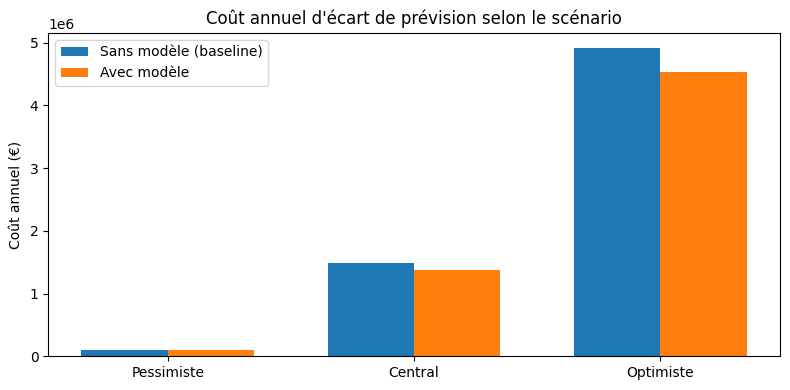

In [21]:
plt.figure(figsize=(8, 4))
positions = np.arange(len(tableau_roi))
largeur = 0.35
plt.bar(positions - largeur / 2, tableau_roi["Coût sans modèle (€)"], largeur, label="Sans modèle (baseline)")
plt.bar(positions + largeur / 2, tableau_roi["Coût avec modèle (€)"], largeur, label="Avec modèle")
plt.xticks(positions, tableau_roi["Scénario"])
plt.title("Coût annuel d'écart de prévision selon le scénario")
plt.ylabel("Coût annuel (€)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "08_cout_scenarios.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture (à compléter)** : le projet reste-t-il rentable dans le scénario pessimiste ? Quelle hypothèse fait le plus bouger le résultat (coût d'écart ? nombre de foyers ?) → c'est celle à valider **en priorité** avec l'entreprise (pilote).

## 3 · Registre des risques (axe 9)
| Risque | Probabilité | Impact | Mesure de réduction |
|---|---|---|---|
| Un seul foyer dans les données : le modèle ne généralise pas à d'autres foyers | Élevée | Élevé | Pilote sur un échantillon de foyers variés avant déploiement ; réentraînement par segment |
| Données anciennes (2006-2010) : habitudes et équipements ont changé | Élevée | Moyen | Réentraîner sur des données récentes ; suivre la MAE chaque mois |
| Coût réel d'un écart différent de nos hypothèses | Moyenne | Élevé | Mesurer le coût réel pendant un pilote de 3 mois (cf. sensibilité) |
| Événements imprévisibles (vacances, télétravail, vague de froid) | Moyenne | Moyen | Ajouter jours fériés / météo ; alerte si l'erreur dépasse un seuil |
| Données personnelles (consommation = habitudes de vie, RGPD) | Moyenne | Élevé | Agréger, pseudonymiser, durée de conservation limitée, consentement |
| Panne de capteur / jours manquants en production | Moyenne | Moyen | Règle de repli sur la baseline « même jour semaine précédente » |
| Coût énergétique de l'entraînement disproportionné | Faible | Faible | Modèles légers (régression, forêt), réentraînement trimestriel |

## 4 · Recommandation (à compléter)
*Executive summary en 3 phrases :* « Nous proposons de … Sur des données jamais vues, le modèle réduit l'erreur de prévision de X % par rapport à … Sous nos hypothèses, le gain est estimé à … € par an pour un coût de … € ; nous recommandons un pilote de 3 mois pour valider … »